Sara de los angeles Carmona Catalan

Media: 3.980  (teórica 4)
Varianza: 1.319  (teórica 1.333)
P(servicio > 5): 0.241  (teórica 0.25)


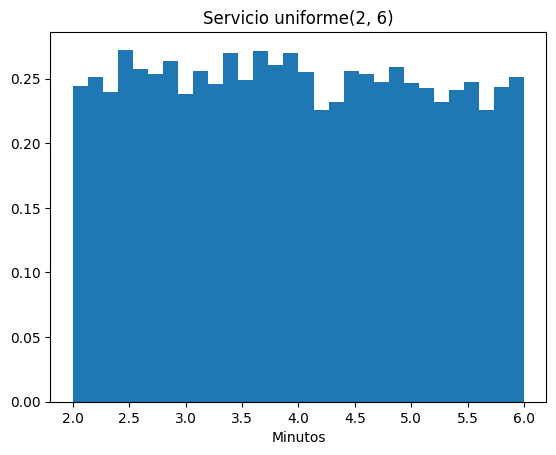

In [5]:
import random, math
import matplotlib.pyplot as plt

random.seed(2026)

def uniforme(a, b):
    return a + (b - a) * random.random()

n = 10_000
servicios = [uniforme(2, 6) for _ in range(n)]

media = sum(servicios) / n
varianza = sum((x - media) ** 2 for x in servicios) / n
prop_mayor5 = sum(x > 5 for x in servicios) / n

print(f"Media: {media:.3f}  (teórica 4)")
print(f"Varianza: {varianza:.3f}  (teórica 1.333)")
print(f"P(servicio > 5): {prop_mayor5:.3f}  (teórica 0.25)")

plt.hist(servicios, bins=30, density=True)
plt.title("Servicio uniforme(2, 6)")
plt.xlabel("Minutos")
plt.show()

Media: 2.955  (teórica 3)
P(llegada < 1 min): 0.286  (teórica 0.283)


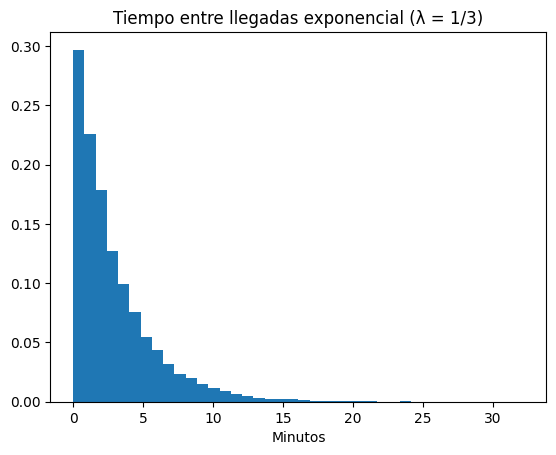

In [6]:
random.seed(2026)

lam = 1 / 3

def exponencial(lam):
    u = random.random()
    return -math.log(1 - u) / lam      # transformada inversa

llegadas = [exponencial(lam) for _ in range(n)]

media = sum(llegadas) / n
prop_menor1 = sum(x < 1 for x in llegadas) / n
teorica_menor1 = 1 - math.exp(-lam * 1)

print(f"Media: {media:.3f}  (teórica 3)")
print(f"P(llegada < 1 min): {prop_menor1:.3f}  (teórica {teorica_menor1:.3f})")

plt.hist(llegadas, bins=40, density=True)
plt.title("Tiempo entre llegadas exponencial (λ = 1/3)")
plt.xlabel("Minutos")
plt.show()

La transformada inversa funciona porque la CDF de la exponencial es F(x) = 1 − e^(−λx). Si U es uniforme(0,1), igualamos U = F(X) y despejamos X = −ln(1−U)/λ, que sale con distribución exponencial. La forma del histograma (muchos valores pequeños y una cola larga) significa que son comunes las llegadas muy seguidas y raras las esperas largas.

In [7]:
random.seed(2026)
lib = [random.expovariate(1 / 3) for _ in range(n)]

print(f"Media mía:         {sum(llegadas)/n:.3f}")
print(f"Media expovariate: {sum(lib)/n:.3f}")

Media mía:         2.955
Media expovariate: 2.955


Mía (Box-Müller): media=8.015, desv=1.493
random.gauss:     media=8.005, desv=1.491


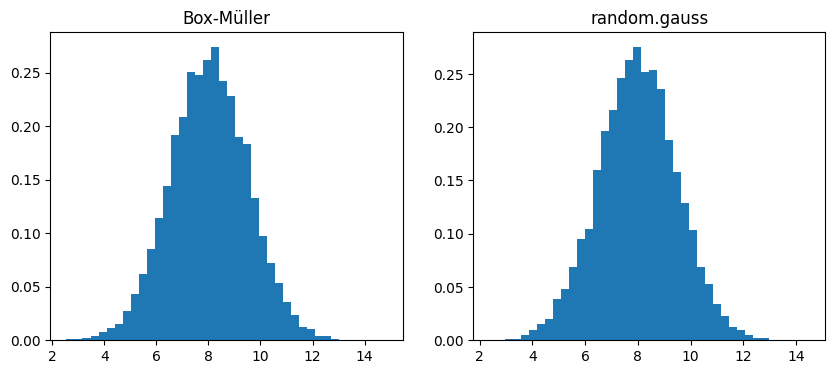

In [8]:
import random, math
import matplotlib.pyplot as plt

random.seed(2026)

def normal(mu, sigma):
    u1 = random.random()
    u2 = random.random()
    z = math.sqrt(-2 * math.log(1 - u1)) * math.cos(2 * math.pi * u2)   # Box-Müller
    return mu + sigma * z

n = 10_000
mios = [normal(8, 1.5) for _ in range(n)]

random.seed(2026)
lib = [random.gauss(8, 1.5) for _ in range(n)]

def media_desv(x):
    m = sum(x) / len(x)
    return m, math.sqrt(sum((v - m) ** 2 for v in x) / len(x))

print("Mía (Box-Müller): media=%.3f, desv=%.3f" % media_desv(mios))
print("random.gauss:     media=%.3f, desv=%.3f" % media_desv(lib))

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].hist(mios, bins=40, density=True); ejes[0].set_title("Box-Müller")
ejes[1].hist(lib, bins=40, density=True);  ejes[1].set_title("random.gauss")
plt.show()

In [9]:
random.seed(2026)

def corrida(n_clientes=20):
    llegada = 0.0
    fin_anterior = 0.0
    total_espera = 0.0
    for _ in range(n_clientes):
        llegada += exponencial(1 / 2)          # media 2 min
        inicio = max(llegada, fin_anterior)
        total_espera += inicio - llegada
        fin_anterior = inicio + uniforme(1, 4) # servicio media 2.5
    return total_espera / n_clientes

resultados = [corrida() for _ in range(500)]
print(f"Espera promedio (500 corridas): {sum(resultados)/500:.3f} min")

Espera promedio (500 corridas): 7.187 min


In [10]:
random.seed(2026)

def corrida_exp(n_clientes=20):
    llegada = 0.0
    fin_anterior = 0.0
    total_espera = 0.0
    for _ in range(n_clientes):
        llegada += exponencial(1 / 2)
        inicio = max(llegada, fin_anterior)
        total_espera += inicio - llegada
        fin_anterior = inicio + exponencial(1 / 2.5)   # media 2.5
    return total_espera / n_clientes

resultados_exp = [corrida_exp() for _ in range(500)]
print(f"Espera promedio con servicio exponencial: {sum(resultados_exp)/500:.3f} min")

Espera promedio con servicio exponencial: 8.566 min
